In [1]:
import numpy as np

In [2]:
import pandas as pd

In [3]:
unic=pd.read_csv("Unicorn_Companies.csv")

In [4]:
unic

,Company,Valuation,Date Joined,Industry,City,Country,Continent,Year Founded,Funding,Select Investors
0,Bytedance,$180B,2017-04-07,Artificial intelligence,Beijing,China,Asia,2012,$8B,"Sequoia Capital China, SIG Asia Investments, S..."
1,SpaceX,$100B,2012-12-01,Other,Hawthorne,United States,North America,2002,$7B,"Founders Fund, Draper Fisher Jurvetson, Rothen..."
2,SHEIN,$100B,2018-07-03,E-commerce & direct-to-consumer,Shenzhen,China,Asia,2008,$2B,"Tiger Global Management, Sequoia Capital China..."
3,Stripe,$95B,2014-01-23,Fintech,San Francisco,United States,North America,2010,$2B,"Khosla Ventures, LowercaseCapital, capitalG"
4,Klarna,$46B,2011-12-12,Fintech,Stockholm,Sweden,Europe,2005,$4B,"Institutional Venture Partners, Sequoia Capita..."
...,...,...,...,...,...,...,...,...,...,...
1069,Zhaogang,$1B,2017-06-29,E-commerce & direct-to-consumer,Shanghai,China,Asia,2012,$379M,"K2 Ventures, Matrix Partners China, IDG Capital"
1070,Zhuan Zhuan,$1B,2017-04-18,E-commerce & direct-to-consumer,Beijing,China,Asia,2015,$990M,"58.com, Tencent Holdings"
1071,Zihaiguo,$1B,2021-05-06,Consumer & retail,Chongqing,China,Asia,2018,$80M,"Xingwang Investment Management, China Capital ..."
1072,Zopa,$1B,2021-10-19,Fintech,London,United Kingdom,Europe,2005,$792M,"IAG Capital Partners, Augmentum Fintech, North..."


In [5]:
unic.isnull().sum()

Company              0
Valuation            0
Date Joined          0
Industry             0
City                16
Country              0
Continent            0
Year Founded         0
Funding              0
Select Investors     1
dtype: int64

In [6]:
unic.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1074 entries, 0 to 1073
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Company           1074 non-null   object
 1   Valuation         1074 non-null   object
 2   Date Joined       1074 non-null   object
 3   Industry          1074 non-null   object
 4   City              1058 non-null   object
 5   Country           1074 non-null   object
 6   Continent         1074 non-null   object
 7   Year Founded      1074 non-null   int64 
 8   Funding           1074 non-null   object
 9   Select Investors  1073 non-null   object
dtypes: int64(1), object(9)
memory usage: 84.0+ KB


In [7]:
unic['Funding'].value_counts()

Funding
$1B        60
$2B        30
Unknown    12
$200M      12
$4B         9
           ..
$717M       1
$101M       1
$19M        1
$946M       1
$620M       1
Name: count, Length: 539, dtype: int64

In [8]:
unic[unic['Funding']=='Unknown']

,Company,Valuation,Date Joined,Industry,City,Country,Continent,Year Founded,Funding,Select Investors
215,SSENSE,$4B,2021-06-08,E-commerce & direct-to-consumer,Montreal,Canada,North America,2003,Unknown,Sequoia Capital
424,Uplight,$2B,2021-03-03,Other,Boulder,United States,North America,2019,Unknown,"Rubicon Technology Partners, Max Ventures, Inc..."
567,ISN,$2B,2020-12-17,"Supply chain, logistics, & delivery",Dallas,United States,North America,2001,Unknown,Blackstone
639,SITECH DEV,$1B,2019-05-16,Other,Guiyang,China,Asia,2017,Unknown,China Prosperity Capital
651,Xiaobing,$1B,2021-07-12,Fintech,Beijing,China,Asia,2020,Unknown,"NetEase Capital, Northern Light Venture Capita..."
717,Veepee,$1B,2007-07-02,E-commerce & direct-to-consumer,La Plaine Saint-Denis,France,Europe,2001,Unknown,"Summit Partners, Qatar Holding"
733,DistroKid,$1B,2021-08-16,Internet software & services,New York,United States,North America,2013,Unknown,"Insight Partners, Silversmith Capital Partners..."
866,Assembly,$1B,2021-09-21,Internet software & services,Culver City,United States,North America,2019,Unknown,"Advent International, PSG, Providence Equity P..."
890,Carson Group,$1B,2021-07-14,Fintech,Lincoln,United States,North America,2012,Unknown,Bain Capital
945,Iodine Software,$1B,2021-12-01,Data management & analytics,Austin,United States,North America,2010,Unknown,"Advent International, Bain Capital Ventures, S..."


In [9]:
unic['Funding']=unic['Funding'].replace({"Unknown":'$1B'})

In [10]:
unic['Valuation'] = unic['Valuation'].map(lambda x: int(x.replace('$', '').replace('B', '')) * 1000000000)

In [11]:
def convert(x):
    if x.endswith('B'):
        return int(x.replace('$', '').replace('B', '')) * 1000000000
    elif x.endswith('M'):
        return int(x.replace('$', '').replace('M', '')) * 1000000

unic['Funding'] = unic['Funding'].map(convert)

In [12]:
print(unic.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1074 entries, 0 to 1073
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Company           1074 non-null   object
 1   Valuation         1074 non-null   int64 
 2   Date Joined       1074 non-null   object
 3   Industry          1074 non-null   object
 4   City              1058 non-null   object
 5   Country           1074 non-null   object
 6   Continent         1074 non-null   object
 7   Year Founded      1074 non-null   int64 
 8   Funding           1074 non-null   int64 
 9   Select Investors  1073 non-null   object
dtypes: int64(3), object(7)
memory usage: 84.0+ KB
None


In [13]:
#converting date joined to date data type
unic["Date Joined"]=pd.to_datetime(unic['Date Joined'])

In [14]:
#converting year founded to date data type
unic['Year Founded']=pd.to_datetime(unic['Year Founded'],format='%Y').dt.year

In [15]:
unic.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1074 entries, 0 to 1073
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   Company           1074 non-null   object        
 1   Valuation         1074 non-null   int64         
 2   Date Joined       1074 non-null   datetime64[ns]
 3   Industry          1074 non-null   object        
 4   City              1058 non-null   object        
 5   Country           1074 non-null   object        
 6   Continent         1074 non-null   object        
 7   Year Founded      1074 non-null   int32         
 8   Funding           1074 non-null   int64         
 9   Select Investors  1073 non-null   object        
dtypes: datetime64[ns](1), int32(1), int64(2), object(6)
memory usage: 79.8+ KB


In [16]:
# checking for null values
print(unic.isnull().sum())

Company              0
Valuation            0
Date Joined          0
Industry             0
City                16
Country              0
Continent            0
Year Founded         0
Funding              0
Select Investors     1
dtype: int64


In [17]:
# checking for duplicate rows
print(unic.duplicated().sum())

0


In [18]:
unic[unic["City"].isnull()]

,Company,Valuation,Date Joined,Industry,City,Country,Continent,Year Founded,Funding,Select Investors
12,FTX,32000000000,2021-07-20,Fintech,NaN,Bahamas,North America,2018,2000000000,"Sequoia Capital, Thoma Bravo, Softbank"
170,HyalRoute,4000000000,2020-05-26,Mobile & telecommunications,NaN,Singapore,Asia,2015,263000000,Kuang-Chi
242,Moglix,3000000000,2021-05-17,E-commerce & direct-to-consumer,NaN,Singapore,Asia,2015,471000000,"Jungle Ventures, Accel, Venture Highway"
251,Trax,3000000000,2019-07-22,Artificial intelligence,NaN,Singapore,Asia,2010,1000000000,"Hopu Investment Management, Boyu Capital, DC T..."
325,Amber Group,3000000000,2021-06-21,Fintech,NaN,Hong Kong,Asia,2015,328000000,"Tiger Global Management, Tiger Brokers, DCM Ve..."
382,Ninja Van,2000000000,2021-09-27,"Supply chain, logistics, & delivery",NaN,Singapore,Asia,2014,975000000,"B Capital Group, Monk's Hill Ventures, Dynamic..."
541,Advance Intelligence Group,2000000000,2021-09-23,Artificial intelligence,NaN,Singapore,Asia,2016,536000000,"Vision Plus Capital, GSR Ventures, ZhenFund"
811,Carousell,1000000000,2021-09-15,E-commerce & direct-to-consumer,NaN,Singapore,Asia,2012,288000000,"500 Global, Rakuten Ventures, Golden Gate Vent..."
848,Matrixport,1000000000,2021-06-01,Fintech,NaN,Singapore,Asia,2019,100000000,"Dragonfly Captial, Qiming Venture Partners, DS..."
880,bolttech,1000000000,2021-07-01,Fintech,NaN,Singapore,Asia,2018,210000000,"Mundi Ventures, Doqling Capital Partners, Acti..."


In [19]:
unic["City"].mode()

0    San Francisco
Name: City, dtype: object

In [20]:
unic[unic['Select Investors'].isnull()]

,Company,Valuation,Date Joined,Industry,City,Country,Continent,Year Founded,Funding,Select Investors
629,LinkSure Network,1000000000,2015-01-01,Mobile & telecommunications,Shanghai,China,Asia,2013,52000000,NaN


In [21]:
print(unic['Select Investors'].fillna('Unkwon',inplace=True))

None


C:\Users\LENOVO\AppData\Local\Temp\ipykernel_10076\1449703601.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  print(unic['Select Investors'].fillna('Unkwon',inplace=True))


In [22]:
unic.iloc[629]

Company                        LinkSure Network
Valuation                            1000000000
Date Joined                 2015-01-01 00:00:00
Industry            Mobile & telecommunications
City                                   Shanghai
Country                                   China
Continent                                  Asia
Year Founded                               2013
Funding                                52000000
Select Investors                         Unkwon
Name: 629, dtype: object

In [23]:
unic[unic['Country']=='Bahamas']

,Company,Valuation,Date Joined,Industry,City,Country,Continent,Year Founded,Funding,Select Investors
12,FTX,32000000000,2021-07-20,Fintech,NaN,Bahamas,North America,2018,2000000000,"Sequoia Capital, Thoma Bravo, Softbank"


In [24]:
unic.loc[unic['Country']=='Bahamas','City']=unic.loc[unic['Country']=='Bahamas','City'].fillna('Nassau')

In [25]:
unic[unic['City'].isnull()]

,Company,Valuation,Date Joined,Industry,City,Country,Continent,Year Founded,Funding,Select Investors
170,HyalRoute,4000000000,2020-05-26,Mobile & telecommunications,NaN,Singapore,Asia,2015,263000000,Kuang-Chi
242,Moglix,3000000000,2021-05-17,E-commerce & direct-to-consumer,NaN,Singapore,Asia,2015,471000000,"Jungle Ventures, Accel, Venture Highway"
251,Trax,3000000000,2019-07-22,Artificial intelligence,NaN,Singapore,Asia,2010,1000000000,"Hopu Investment Management, Boyu Capital, DC T..."
325,Amber Group,3000000000,2021-06-21,Fintech,NaN,Hong Kong,Asia,2015,328000000,"Tiger Global Management, Tiger Brokers, DCM Ve..."
382,Ninja Van,2000000000,2021-09-27,"Supply chain, logistics, & delivery",NaN,Singapore,Asia,2014,975000000,"B Capital Group, Monk's Hill Ventures, Dynamic..."
541,Advance Intelligence Group,2000000000,2021-09-23,Artificial intelligence,NaN,Singapore,Asia,2016,536000000,"Vision Plus Capital, GSR Ventures, ZhenFund"
811,Carousell,1000000000,2021-09-15,E-commerce & direct-to-consumer,NaN,Singapore,Asia,2012,288000000,"500 Global, Rakuten Ventures, Golden Gate Vent..."
848,Matrixport,1000000000,2021-06-01,Fintech,NaN,Singapore,Asia,2019,100000000,"Dragonfly Captial, Qiming Venture Partners, DS..."
880,bolttech,1000000000,2021-07-01,Fintech,NaN,Singapore,Asia,2018,210000000,"Mundi Ventures, Doqling Capital Partners, Acti..."
889,Carro,1000000000,2021-06-14,E-commerce & direct-to-consumer,NaN,Singapore,Asia,2015,595000000,"SingTel Innov8, Alpha JWC Ventures, Golden Gat..."


In [26]:
unic[unic['Country']=='Singapore']

,Company,Valuation,Date Joined,Industry,City,Country,Continent,Year Founded,Funding,Select Investors
170,HyalRoute,4000000000,2020-05-26,Mobile & telecommunications,NaN,Singapore,Asia,2015,263000000,Kuang-Chi
242,Moglix,3000000000,2021-05-17,E-commerce & direct-to-consumer,NaN,Singapore,Asia,2015,471000000,"Jungle Ventures, Accel, Venture Highway"
251,Trax,3000000000,2019-07-22,Artificial intelligence,NaN,Singapore,Asia,2010,1000000000,"Hopu Investment Management, Boyu Capital, DC T..."
382,Ninja Van,2000000000,2021-09-27,"Supply chain, logistics, & delivery",NaN,Singapore,Asia,2014,975000000,"B Capital Group, Monk's Hill Ventures, Dynamic..."
541,Advance Intelligence Group,2000000000,2021-09-23,Artificial intelligence,NaN,Singapore,Asia,2016,536000000,"Vision Plus Capital, GSR Ventures, ZhenFund"
811,Carousell,1000000000,2021-09-15,E-commerce & direct-to-consumer,NaN,Singapore,Asia,2012,288000000,"500 Global, Rakuten Ventures, Golden Gate Vent..."
848,Matrixport,1000000000,2021-06-01,Fintech,NaN,Singapore,Asia,2019,100000000,"Dragonfly Captial, Qiming Venture Partners, DS..."
880,bolttech,1000000000,2021-07-01,Fintech,NaN,Singapore,Asia,2018,210000000,"Mundi Ventures, Doqling Capital Partners, Acti..."
889,Carro,1000000000,2021-06-14,E-commerce & direct-to-consumer,NaN,Singapore,Asia,2015,595000000,"SingTel Innov8, Alpha JWC Ventures, Golden Gat..."
980,NIUM,1000000000,2021-07-13,Fintech,NaN,Singapore,Asia,2014,285000000,"Vertex Ventures SE Asia, Global Founders Capit..."


In [27]:
unic.loc[unic['Country']=='Singapore','City']=unic.loc[unic['Country']=='Singapore','City'].fillna('Singapore')

In [28]:
unic[unic['Country']=='Singapore']

,Company,Valuation,Date Joined,Industry,City,Country,Continent,Year Founded,Funding,Select Investors
170,HyalRoute,4000000000,2020-05-26,Mobile & telecommunications,Singapore,Singapore,Asia,2015,263000000,Kuang-Chi
242,Moglix,3000000000,2021-05-17,E-commerce & direct-to-consumer,Singapore,Singapore,Asia,2015,471000000,"Jungle Ventures, Accel, Venture Highway"
251,Trax,3000000000,2019-07-22,Artificial intelligence,Singapore,Singapore,Asia,2010,1000000000,"Hopu Investment Management, Boyu Capital, DC T..."
382,Ninja Van,2000000000,2021-09-27,"Supply chain, logistics, & delivery",Singapore,Singapore,Asia,2014,975000000,"B Capital Group, Monk's Hill Ventures, Dynamic..."
541,Advance Intelligence Group,2000000000,2021-09-23,Artificial intelligence,Singapore,Singapore,Asia,2016,536000000,"Vision Plus Capital, GSR Ventures, ZhenFund"
811,Carousell,1000000000,2021-09-15,E-commerce & direct-to-consumer,Singapore,Singapore,Asia,2012,288000000,"500 Global, Rakuten Ventures, Golden Gate Vent..."
848,Matrixport,1000000000,2021-06-01,Fintech,Singapore,Singapore,Asia,2019,100000000,"Dragonfly Captial, Qiming Venture Partners, DS..."
880,bolttech,1000000000,2021-07-01,Fintech,Singapore,Singapore,Asia,2018,210000000,"Mundi Ventures, Doqling Capital Partners, Acti..."
889,Carro,1000000000,2021-06-14,E-commerce & direct-to-consumer,Singapore,Singapore,Asia,2015,595000000,"SingTel Innov8, Alpha JWC Ventures, Golden Gat..."
980,NIUM,1000000000,2021-07-13,Fintech,Singapore,Singapore,Asia,2014,285000000,"Vertex Ventures SE Asia, Global Founders Capit..."


In [29]:
unic.loc[unic['Country']=='Hong Kong','City']=unic.loc[unic['Country']=='Hong Kong','City'].fillna('Central')

In [30]:
unic[unic['Country']=='Hong Kong']

,Company,Valuation,Date Joined,Industry,City,Country,Continent,Year Founded,Funding,Select Investors
56,Lalamove,10000000000,2019-02-21,"Supply chain, logistics, & delivery",Cheung Sha Wan,Hong Kong,Asia,2013,2000000000,"MindWorks Ventures, Shunwei Capital Partners, ..."
325,Amber Group,3000000000,2021-06-21,Fintech,Central,Hong Kong,Asia,2015,328000000,"Tiger Global Management, Tiger Brokers, DCM Ve..."
595,Trendy Group International,2000000000,2012-02-13,Consumer & retail,Kowloon,Hong Kong,Asia,1999,200000000,L Capital Partners
720,Klook,1000000000,2018-08-07,Travel,Central,Hong Kong,Asia,2014,722000000,"Sequoia Capital China, Goldman Sachs, Matrix P..."
893,Cider,1000000000,2021-09-02,E-commerce & direct-to-consumer,Central,Hong Kong,Asia,2020,140000000,"Andreessen Horowitz, DST Global, IDG Capital"
1061,WeLab,1000000000,2017-11-08,Fintech,Central,Hong Kong,Asia,2013,871000000,"Sequoia Capital China, ING, Alibaba Entreprene..."


In [31]:
unic[unic['Continent']=='Asia']

,Company,Valuation,Date Joined,Industry,City,Country,Continent,Year Founded,Funding,Select Investors
0,Bytedance,180000000000,2017-04-07,Artificial intelligence,Beijing,China,Asia,2012,8000000000,"Sequoia Capital China, SIG Asia Investments, S..."
2,SHEIN,100000000000,2018-07-03,E-commerce & direct-to-consumer,Shenzhen,China,Asia,2008,2000000000,"Tiger Global Management, Sequoia Capital China..."
15,BYJU's,22000000000,2017-07-25,Edtech,Bengaluru,India,Asia,2008,4000000000,"Tencent Holdings, Lightspeed India Partners, S..."
16,J&T Express,20000000000,2021-04-07,"Supply chain, logistics, & delivery",Jakarta,Indonesia,Asia,2015,5000000000,"Hillhouse Capital Management, Boyu Capital, Se..."
17,Xiaohongshu,20000000000,2016-03-31,E-commerce & direct-to-consumer,Shanghai,China,Asia,2013,918000000,"GGV Capital, ZhenFund, Tencent"
...,...,...,...,...,...,...,...,...,...,...
1066,YH Global,1000000000,2017-09-21,"Supply chain, logistics, & delivery",Shenzhen,China,Asia,1997,182000000,"Co-Energy Finance, Grandland"
1068,Yunxuetang,1000000000,2021-03-29,Edtech,Suzhou,China,Asia,2011,389000000,"Matrix Partners China, Sequoia Capital China, ..."
1069,Zhaogang,1000000000,2017-06-29,E-commerce & direct-to-consumer,Shanghai,China,Asia,2012,379000000,"K2 Ventures, Matrix Partners China, IDG Capital"
1070,Zhuan Zhuan,1000000000,2017-04-18,E-commerce & direct-to-consumer,Beijing,China,Asia,2015,990000000,"58.com, Tencent Holdings"


In [32]:
# finding total number of companies 
print(unic['Company'].nunique())

1073


In [33]:
unic[unic['Company'].duplicated()]

,Company,Valuation,Date Joined,Industry,City,Country,Continent,Year Founded,Funding,Select Investors
44,Bolt,11000000000,2021-10-08,Fintech,San Francisco,United States,North America,2014,1000000000,"Activant Capital, Tribe Capital, General Atlantic"


In [34]:
unic[unic['Company']=='Bolt']

,Company,Valuation,Date Joined,Industry,City,Country,Continent,Year Founded,Funding,Select Investors
40,Bolt,11000000000,2018-05-29,Auto & transportation,Tallinn,Estonia,Europe,2013,1000000000,"Didi Chuxing, Diamler, TMT Investments"
44,Bolt,11000000000,2021-10-08,Fintech,San Francisco,United States,North America,2014,1000000000,"Activant Capital, Tribe Capital, General Atlantic"


In [35]:
print(unic.isnull().sum())

Company             0
Valuation           0
Date Joined         0
Industry            0
City                0
Country             0
Continent           0
Year Founded        0
Funding             0
Select Investors    0
dtype: int64


In [36]:
unic['Continent'].value_counts()

Continent
North America    589
Asia             310
Europe           143
South America     21
Oceania            8
Africa             3
Name: count, dtype: int64

In [37]:
unic['Country'].value_counts()

Country
United States           562
China                   173
India                    65
United Kingdom           43
Germany                  26
France                   24
Israel                   20
Canada                   19
Brazil                   16
Singapore                12
South Korea              12
Australia                 8
Hong Kong                 6
Mexico                    6
Indonesia                 6
Netherlands               6
Sweden                    6
Switzerland               5
Japan                     5
Ireland                   5
Finland                   4
Norway                    4
United Arab Emirates      3
Turkey                    3
Spain                     3
Belgium                   3
Chile                     2
South Africa              2
Philippines               2
Thailand                  2
Estonia                   2
Vietnam                   2
Austria                   2
Colombia                  2
Denmark                   2
Argentina   

In [38]:
unic[unic['Country']=='India']

,Company,Valuation,Date Joined,Industry,City,Country,Continent,Year Founded,Funding,Select Investors
15,BYJU's,22000000000,2017-07-25,Edtech,Bengaluru,India,Asia,2008,4000000000,"Tencent Holdings, Lightspeed India Partners, S..."
41,Swiggy,11000000000,2018-06-21,"Supply chain, logistics, & delivery",Bengaluru,India,Asia,2014,5000000000,"Accel India, SAIF Partners, Norwest Venture Pa..."
48,OYO Rooms,10000000000,2018-09-25,Travel,Gurugram,India,Asia,2012,3000000000,"SoftBank Group, Sequoia Capital India,Lightspe..."
71,Dream11,8000000000,2019-04-09,Internet software & services,Mumbai,India,Asia,2007,2000000000,"Kaalari Capital, Tencent Holdings, Steadview C..."
74,Razorpay,8000000000,2020-10-11,Fintech,Bengaluru,India,Asia,2013,742000000,"Sequoia Capital India, Tiger Global Management..."
...,...,...,...,...,...,...,...,...,...,...
955,Licious,1000000000,2021-10-05,E-commerce & direct-to-consumer,Bengaluru,India,Asia,2015,489000000,"3one4 Capital Partners, Bertelsmann India Inve..."
967,Mensa Brands,1000000000,2021-11-16,Other,Bengaluru,India,Asia,2021,218000000,"Accel, Falcon Edge Capital, Norwest Venture Pa..."
981,NoBroker,1000000000,2021-11-23,Internet software & services,Bengaluru,India,Asia,2014,424000000,"General Atlantic, Elevation Capital, BEENEXT"
1026,Slice,1000000000,2021-11-28,Fintech,Bengaluru,India,Asia,2015,249000000,"Gunosy Capital, Blume Ventures, Das Capital"


In [39]:
#total valuation
print("Total Valuation of unicorn companies: ",unic['Valuation'].sum())

Total Valuation of unicorn companies:  3711000000000


In [40]:
# avg valuation
print("Average Valuation of unicorn companies: ",unic['Valuation'].mean())

Average Valuation of unicorn companies:  3455307262.5698323


In [41]:
# top 10 companies with highest valuations
a=unic.groupby('Company')['Valuation'].sum().sort_values(ascending=False).head(10)
print("Top 10 companies with highest valuations\n", a)

Top 10 companies with highest valuations
 Company
Bytedance       180000000000
SpaceX          100000000000
SHEIN           100000000000
Stripe           95000000000
Klarna           46000000000
Checkout.com     40000000000
Canva            40000000000
Instacart        39000000000
JUUL Labs        38000000000
Databricks       38000000000
Name: Valuation, dtype: int64


In [42]:
# Industry with most unicorn companies
b=unic.groupby('Industry')['Company'].nunique().sort_values(ascending=False).head(1)
print("Industry with most unicorn companies:\n",b)

Industry with most unicorn companies:
 Industry
Fintech    224
Name: Company, dtype: int64


In [43]:
c=unic.groupby('Industry').agg(total_valaution=('Valuation','sum'),average_valution=('Valuation','mean'))
print(c.sort_values('total_valaution',ascending=False))

                                     total_valaution  average_valution
Industry                                                              
Fintech                                 882000000000      3.937500e+09
Internet software & services            595000000000      2.902439e+09
E-commerce & direct-to-consumer         426000000000      3.837838e+09
Artificial intelligence                 361000000000      4.945205e+09
Other                                   252000000000      4.344828e+09
Health                                  198000000000      2.675676e+09
Supply chain, logistics, & delivery     177000000000      3.105263e+09
Data management & analytics             136000000000      3.317073e+09
Cybersecurity                           129000000000      2.580000e+09
Consumer & retail                       106000000000      4.240000e+09
Edtech                                  100000000000      3.571429e+09
Auto & transportation                    99000000000      3.193548e+09
Hardwa

In [44]:
d=unic.groupby('Continent')['Company'].nunique().sort_values(ascending=False).head(1)
print('Continents with most unicorn companies\n',d)
cntr=unic.groupby('Country')['Company'].nunique().sort_values(ascending=False).head(1)
print('Country with most unicorn companies\n',cntr)

Continents with most unicorn companies
 Continent
North America    589
Name: Company, dtype: int64
Country with most unicorn companies
 Country
United States    562
Name: Company, dtype: int64


In [45]:
city=unic.groupby('City')['Company'].nunique().sort_values(ascending=False).head(1)
print('City with most unicorn companies\n',city)

City with most unicorn companies
 City
San Francisco    152
Name: Company, dtype: int64


In [46]:
unic['Joined Year']=unic['Date Joined'].dt.year
unic.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1074 entries, 0 to 1073
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   Company           1074 non-null   object        
 1   Valuation         1074 non-null   int64         
 2   Date Joined       1074 non-null   datetime64[ns]
 3   Industry          1074 non-null   object        
 4   City              1074 non-null   object        
 5   Country           1074 non-null   object        
 6   Continent         1074 non-null   object        
 7   Year Founded      1074 non-null   int32         
 8   Funding           1074 non-null   int64         
 9   Select Investors  1074 non-null   object        
 10  Joined Year       1074 non-null   int32         
dtypes: datetime64[ns](1), int32(2), int64(2), object(6)
memory usage: 84.0+ KB


In [47]:
unic

,Company,Valuation,Date Joined,Industry,City,Country,Continent,Year Founded,Funding,Select Investors,Joined Year
0,Bytedance,180000000000,2017-04-07,Artificial intelligence,Beijing,China,Asia,2012,8000000000,"Sequoia Capital China, SIG Asia Investments, S...",2017
1,SpaceX,100000000000,2012-12-01,Other,Hawthorne,United States,North America,2002,7000000000,"Founders Fund, Draper Fisher Jurvetson, Rothen...",2012
2,SHEIN,100000000000,2018-07-03,E-commerce & direct-to-consumer,Shenzhen,China,Asia,2008,2000000000,"Tiger Global Management, Sequoia Capital China...",2018
3,Stripe,95000000000,2014-01-23,Fintech,San Francisco,United States,North America,2010,2000000000,"Khosla Ventures, LowercaseCapital, capitalG",2014
4,Klarna,46000000000,2011-12-12,Fintech,Stockholm,Sweden,Europe,2005,4000000000,"Institutional Venture Partners, Sequoia Capita...",2011
...,...,...,...,...,...,...,...,...,...,...,...
1069,Zhaogang,1000000000,2017-06-29,E-commerce & direct-to-consumer,Shanghai,China,Asia,2012,379000000,"K2 Ventures, Matrix Partners China, IDG Capital",2017
1070,Zhuan Zhuan,1000000000,2017-04-18,E-commerce & direct-to-consumer,Beijing,China,Asia,2015,990000000,"58.com, Tencent Holdings",2017
1071,Zihaiguo,1000000000,2021-05-06,Consumer & retail,Chongqing,China,Asia,2018,80000000,"Xingwang Investment Management, China Capital ...",2021
1072,Zopa,1000000000,2021-10-19,Fintech,London,United Kingdom,Europe,2005,792000000,"IAG Capital Partners, Augmentum Fintech, North...",2021


In [48]:
unic['Years Taken']=unic['Joined Year']-unic['Year Founded']
unic

,Company,Valuation,Date Joined,Industry,City,Country,Continent,Year Founded,Funding,Select Investors,Joined Year,Years Taken
0,Bytedance,180000000000,2017-04-07,Artificial intelligence,Beijing,China,Asia,2012,8000000000,"Sequoia Capital China, SIG Asia Investments, S...",2017,5
1,SpaceX,100000000000,2012-12-01,Other,Hawthorne,United States,North America,2002,7000000000,"Founders Fund, Draper Fisher Jurvetson, Rothen...",2012,10
2,SHEIN,100000000000,2018-07-03,E-commerce & direct-to-consumer,Shenzhen,China,Asia,2008,2000000000,"Tiger Global Management, Sequoia Capital China...",2018,10
3,Stripe,95000000000,2014-01-23,Fintech,San Francisco,United States,North America,2010,2000000000,"Khosla Ventures, LowercaseCapital, capitalG",2014,4
4,Klarna,46000000000,2011-12-12,Fintech,Stockholm,Sweden,Europe,2005,4000000000,"Institutional Venture Partners, Sequoia Capita...",2011,6
...,...,...,...,...,...,...,...,...,...,...,...,...
1069,Zhaogang,1000000000,2017-06-29,E-commerce & direct-to-consumer,Shanghai,China,Asia,2012,379000000,"K2 Ventures, Matrix Partners China, IDG Capital",2017,5
1070,Zhuan Zhuan,1000000000,2017-04-18,E-commerce & direct-to-consumer,Beijing,China,Asia,2015,990000000,"58.com, Tencent Holdings",2017,2
1071,Zihaiguo,1000000000,2021-05-06,Consumer & retail,Chongqing,China,Asia,2018,80000000,"Xingwang Investment Management, China Capital ...",2021,3
1072,Zopa,1000000000,2021-10-19,Fintech,London,United Kingdom,Europe,2005,792000000,"IAG Capital Partners, Augmentum Fintech, North...",2021,16


In [49]:
i=unic.groupby('Industry')['Years Taken'].mean().sort_values(ascending=False)
print("Average years taken by each industry to join unicorn comapnies:\n",i)

Average years taken by each industry to join unicorn comapnies:
 Industry
Health                                 8.189189
Consumer & retail                      8.080000
Data management & analytics            8.073171
Internet software & services           7.868293
Other                                  7.775862
Edtech                                 7.714286
Supply chain, logistics, & delivery    6.929825
Cybersecurity                          6.800000
Travel                                 6.571429
Fintech                                6.544643
E-commerce & direct-to-consumer        6.432432
Mobile & telecommunications            6.315789
Artificial intelligence                5.972603
Hardware                               5.941176
Artificial Intelligence                5.363636
Auto & transportation                  5.032258
Name: Years Taken, dtype: float64


In [50]:
j=unic.groupby('Continent')['Years Taken'].mean().sort_values(ascending=False)
print("Average years taken by each Continent to join unicorn comapnies:\n",j)

Average years taken by each Continent to join unicorn comapnies:
 Continent
Europe           8.251748
Oceania          7.875000
Africa           7.666667
South America    7.047619
North America    6.884550
Asia             6.612903
Name: Years Taken, dtype: float64


In [51]:
f=unic.groupby('Industry')['Funding'].sum().sort_values(ascending=False)
print("Funds provided by each industry:\n",f)

Funds provided by each industry:
 Industry
Fintech                                109996000000
E-commerce & direct-to-consumer         76437000000
Internet software & services            74955000000
Supply chain, logistics, & delivery     45393000000
Artificial intelligence                 43925000000
Other                                   42044000000
Auto & transportation                   35074000000
Health                                  33944000000
Consumer & retail                       26492000000
Cybersecurity                           21932000000
Edtech                                  21875000000
Hardware                                21385000000
Data management & analytics             18981000000
Mobile & telecommunications             15884000000
Travel                                  12626000000
Artificial Intelligence                  2877000000
Name: Funding, dtype: int64


In [52]:
co=unic.groupby('Company')['Funding'].sum().sort_values(ascending=False).head(1)
print("Highest Fund provided by company:\n",co)

Highest Fund provided by company:
 Company
JUUL Labs    14000000000
Name: Funding, dtype: int64


In [53]:
inv=unic.groupby('Select Investors')['Funding'].sum().sort_values(ascending=False).head(10)
print("top 10 Fund provided by investor:\n",inv)

top 10 Fund provided by investor:
 Select Investors
Tiger Global Management                                                               14000000000
Sequoia Capital China, SIG Asia Investments, Sina Weibo, Softbank Group                8000000000
Founders Fund, Draper Fisher Jurvetson, Rothenberg Ventures                            7000000000
Tencent Holdings, KKR, Smash Ventures                                                  7000000000
Accel India, SAIF Partners, Norwest Venture Partners                                   5000000000
KKR, Tencent Holdings, Sequoia Capital China                                           5000000000
Hillhouse Capital Management, Boyu Capital, Sequoia Capital China                      5000000000
Aviation Industry Corporation of China, Essence Financial, Jiangsu Sha Steel Group     5000000000
Sequoia Capital China, GX Capital                                                      4000000000
SoftBank Group, Andreessen Horowitz, Temasek Holdings             

In [54]:
y=unic.groupby('Joined Year')['Company'].count().sort_values(ascending=False)
print("number of comapnies joined in each year\n",y)

number of comapnies joined in each year
 Joined Year
2021    520
2022    116
2020    108
2019    104
2018    103
2017     44
2015     35
2016     21
2014     13
2012      4
2013      3
2011      2
2007      1
Name: Company, dtype: int64


In [55]:
# total valuation and fundings in each year
v=unic.groupby('Joined Year').agg(Total_Funding=('Funding','sum'),Total_Valuation=('Valuation','sum')).sort_values('Total_Funding',ascending=False)
print("Total fundings and valuation in each year\n",v)

Total fundings and valuation in each year
              Total_Funding  Total_Valuation
Joined Year                                
2021          204837000000    1189000000000
2018           92112000000     589000000000
2019           82922000000     457000000000
2020           67283000000     402000000000
2017           49566000000     348000000000
2022           35624000000     200000000000
2016           20830000000      86000000000
2014           18059000000     166000000000
2015           13377000000      84000000000
2012           11858000000     131000000000
2011            5000000000      52000000000
2013            1352000000       6000000000
2007            1000000000       1000000000


In [56]:
invstr=unic['Select Investors'].str.split(',')
invstr=invstr.explode().str.strip()
invstr.value_counts().head(10)

Select Investors
Accel                          60
Andreessen Horowitz            53
Tiger Global Management        53
Sequoia Capital China          48
Sequoia Capital                47
Insight Partners               47
General Catalyst               34
Lightspeed Venture Partners    34
SoftBank Group                 34
Index Ventures                 32
Name: count, dtype: int64

In [57]:
import matplotlib.pyplot as plt

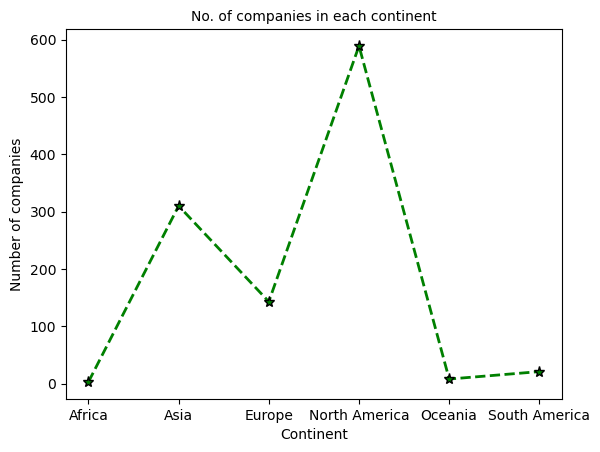

In [58]:
c=unic.groupby('Continent')['Company'].count()
plt.title("No. of companies in each continent",size=10)
plt.xlabel("Continent",size=10)
plt.ylabel("Number of companies",size=10)
plt.plot(c,marker='*',color='g',markeredgecolor='k',linestyle='--',linewidth=2,markersize=8)
plt.show()

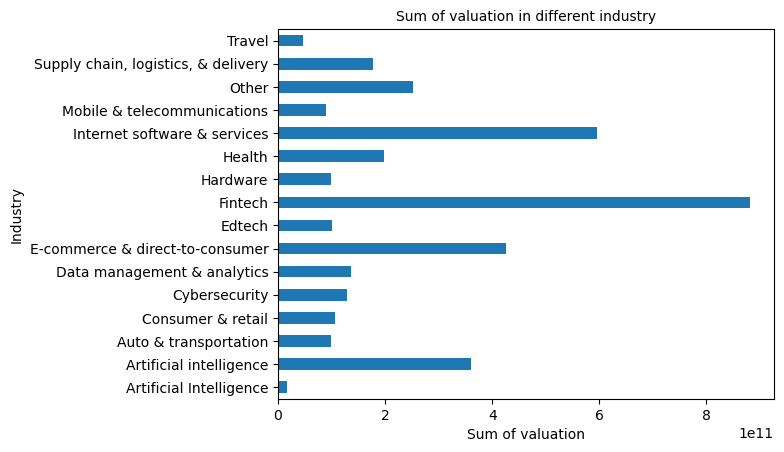

In [59]:
i=unic.groupby('Industry')['Valuation'].sum()
plt.title("Sum of valuation in different industry",size=10,color='k')
i.plot(kind='barh')
plt.xlabel("Sum of valuation",size=10)
plt.ylabel("Industry",size=10)
plt.show()

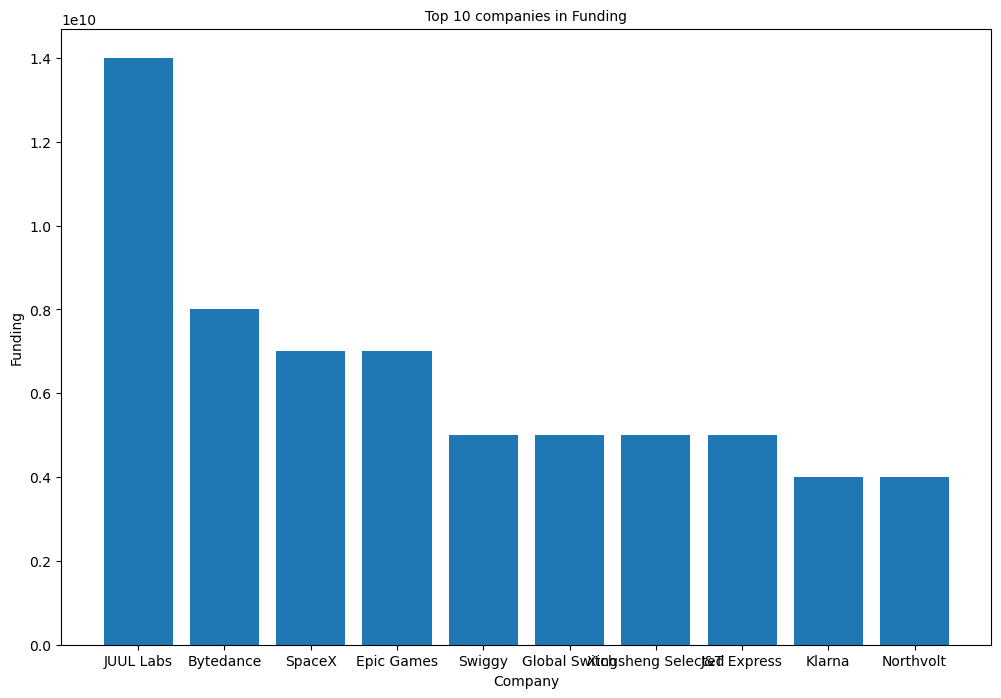

In [60]:
c10=unic.groupby('Company')['Funding'].sum().sort_values(ascending=False).head(10)
x=c10.index
y=c10.values
plt.figure(figsize=(12,8))
plt.title("Top 10 companies in Funding",size=10)
plt.xlabel("Company",size=10)
plt.ylabel("Funding",size=10)
plt.bar(x,y)
plt.show()

In [63]:
#exporting to csv
unic.to_csv("project_unicorn.csv")